## A4 · NumPy

Arrays, whole-array maths, sequences and random numbers.

In [171]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

# Plot defaults: wide 16:9 figures, sharp ("retina") output and slightly smaller text
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({
    "figure.figsize": (6.4, 3.6),
    "figure.dpi": 100,
    "font.size": 9,
    "axes.titlesize": 10,
    "axes.labelsize": 9,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
})

# Same data as sns.load_dataset('penguins'), saved locally so it works offline
df_penguins = pd.read_csv("data/penguins.csv")

### Arrays

#### Creating an array

**A4.01**

`np.array(mylist)`

The `np.array()` function allows us to turn a list into an array that supports whole-array maths. It is useful for calculations on many numbers at once. Alternatively, a pandas Series does the same and adds labels.

An array is like a list, but designed for maths on whole collections of numbers at once.

In [172]:
heights = [165, 187, 164, 172]    # a list
arr = np.array(heights)           # the same numbers as an array
print(arr)
print(type(arr))
print(arr.dtype)

[165 187 164 172]
<class 'numpy.ndarray'>
int64


Lists and arrays behave differently with `*`:

In [173]:
[1, 2] * 2              # list: repeats the list

[1, 2, 1, 2]

In [174]:
np.array([1, 2]) * 2    # array: multiplies each number

array([2, 4])

*See also:* Creating a list (A3) · Maths on a whole array (A4) · Turning a dictionary into a DataFrame (A3)

#### Indexing and slicing an array

**A4.02**

`arr[3], arr[1:4]`

Indexing and slicing allow us to pick out single values or sections of an array. They are useful for selecting values by position, in the same way as for lists. Alternatively, use boolean masks to select by condition instead of position.

Indexing works like lists: start at 0, negative counts from the end, and a slice excludes its end.

In [175]:
arr = np.array([2, 4, 6, 8, 10])
print(arr[3])       # 8
print(arr[1:4])     # [4 6 8]
print(arr[-1])      # 10
print(arr[::2])     # every second value

8
[4 6 8]
10
[ 2  6 10]


*See also:* Picking an item from a list by position (A3) · Slicing a list (A3) · Views and copies of an array slice (A4) · Selecting rows and columns by position lists (B3)

#### Views and copies of an array slice

**A4.03**

`arr[1:4].copy()`

The `.copy()` method allows us to take an independent copy of part of an array. It is useful because a slice of an array shares memory with the original, so editing it changes the original. Alternatively, list slices make copies automatically.

A slice of an **array** shares memory with the original (unlike a list slice), so changing the slice changes the original. Use `.copy()` when an independent copy is needed.

In [176]:
a = np.array([1, 2, 3, 4, 5])
view = a[1:4]
view[0] = 999
print(f"original after changing the view: {a}")   # changed

original after changing the view: [  1 999   3   4   5]


In [177]:
b = np.array([1, 2, 3, 4, 5])
safe = b[1:4].copy()
safe[0] = 999
print(f"original after changing the copy: {b}")   # unchanged

original after changing the copy: [1 2 3 4 5]


*See also:* Copies and aliases of a list (A3) · Indexing and slicing an array (A4) · Checking the shape of an array (A4) · Copying a filtered table (B3)

#### Checking the shape of an array

**A4.04**

`arr.shape, len(arr)`

***(non-examinable)***

The `.shape` attribute and `len()` allow us to see how big an array is. They are useful for checking that the data have the expected size. Alternatively, `.size` gives the total number of elements.

In [178]:
m = np.zeros((2, 3))     # 2 rows, 3 columns
print(m)
print(f"shape = {m.shape}, len = {len(m)}")
print(len(np.array([4, 5, 6])))

[[0. 0. 0.]
 [0. 0. 0.]]
shape = (2, 3), len = 2
3


*See also:* Checking the size of a DataFrame (B1) · Creating an array (A4)

### Maths on whole arrays

#### Maths on a whole array

**A4.05**

`arr + n, arr ** 2, a * b`

Arithmetic operators on arrays allow us to calculate on every element at once. This is useful for converting units or combining columns without a loop. Alternatively, a list comprehension works on plain lists, without NumPy.

Operations apply to every element at once, with no loop needed. Two arrays must have the same shape.

In [179]:
a = np.array([1, 2, 3])
b = np.array([10, 20, 30])
print(a + 10)
print(a ** 2)
print(a * b)       # element by element
print(a / b)

[11 12 13]
[1 4 9]
[10 40 90]
[0.1 0.1 0.1]


In [180]:
np.array([1, 2, 3]) + np.array([1, 2])    # shapes do not match

ValueError: operands could not be broadcast together with shapes (3,) (2,) 

*See also:* Basic arithmetic (A1) · Creating an array (A4) · Adding a calculated column (B4) · Applying maths functions to an array (A4)

#### Applying maths functions to an array

**A4.06**

`np.log10(a), np.log(a), np.sqrt(a)`

Functions such as `np.log10`, `np.sqrt` and `np.exp` allow us to transform every value in an array. They are useful for log-transforming skewed data. Alternatively, the `math` module does the same for a single number only.

NumPy functions work on a whole array (or a single number) at once.

In [181]:
a = np.array([1, 10, 100, 1000])
print(np.log10(a))
print(np.sqrt(a).round(2))
print(np.log(a).round(3))      # natural log
print(np.exp(1))

[0. 1. 2. 3.]
[ 1.    3.16 10.   31.62]
[0.    2.303 4.605 6.908]
2.718281828459045


*See also:* Maths on a whole array (A4) · Adding a column with a NumPy function (B4) · Log-log models (D5)

#### Summarising an array

**A4.07**

`arr.mean(), arr.std(), arr.max()`

Methods like `.mean()`, `.max()` and `.std()` allow us to summarise an array in one call. They are useful for quick descriptive statistics. Alternatively, pandas columns have the same methods, plus `.describe()`.

In [182]:
arr = np.array([2, 4, 6, 8, 10])
pd.Series({"mean": arr.mean(), "max": arr.max(), "min": arr.min(), "sum": arr.sum(), "std": arr.std()}).round(2)

mean     6.00
max     10.00
min      2.00
sum     30.00
std      2.83
dtype: float64

Each statistic is also available as a method on its own, for example `arr.mean()`.

*See also:* Describing the whole table (B5) · Summarising a list with len, sum, max, min (A3) · Choosing the standard deviation formula with `ddof` (A4)

#### Finding the median and percentiles

**A4.08**

`np.median(arr), np.percentile(arr, q)`

The functions `np.median` and `np.percentile` allow us to find the middle value and quartiles of an array. They are useful when outliers would distort the mean. Alternatively, pandas has `.median()` and `.quantile()`.

In [183]:
arr = np.array([2, 4, 6, 8, 10, 100])
print(f"mean      = {arr.mean():.1f}")       # pulled up by the outlier
print(f"median    = {np.median(arr):.1f}")   # not affected much
print(f"quartiles = {np.percentile(arr, [25, 75]).tolist()}")

mean      = 21.7
median    = 7.0
quartiles = [4.5, 9.5]


*See also:* Calculating summary statistics (B5) · Summarising an array (A4)

#### Taking differences and sums of an array

**A4.09**

`np.diff(a), np.sum(a)`

The `np.diff` function allows us to calculate the change between neighbouring values. It is useful for rates of change and the Durbin–Watson test. Alternatively, pandas has `.diff()` for columns.

`np.diff` gives the change between neighbouring values (used in the Durbin–Watson statistic).

In [184]:
a = np.array([1, 4, 9, 16])
print(np.diff(a))        # [3 5 7]
print(np.sum(a))
print(np.sum(np.diff(a) ** 2))

[3 5 7]
30
83


*See also:* Calculating changes between rows (B8) · The Durbin-Watson statistic (D5) · Summarising an array (A4)

#### Choosing the standard deviation formula with `ddof`

**A4.10**

`np.std(x)  vs  Series.std()`

The `ddof` argument allows us to choose between population (n) and sample (n − 1) standard deviation. It is useful when results from NumPy and pandas disagree, because they use different defaults. Alternatively, always use pandas `.std()`, which already gives the sample version.

Watch out: NumPy's `.std()` divides by *n* (`ddof=0`, population). pandas' `.std()` divides by *n − 1* (`ddof=1`, sample). For sample data use `ddof=1` in NumPy to match pandas.

In [185]:
x = np.array([2, 4, 4, 4, 5, 5, 7, 9])
print(f"numpy  ddof=0  : {np.std(x):.3f}")
print(f"numpy  ddof=1  : {np.std(x, ddof=1):.3f}")
print(f"pandas default : {pd.Series(x).std():.3f}")
print(f"pandas ddof=0  : {pd.Series(x).std(ddof=0):.3f}")

numpy  ddof=0  : 2.000
numpy  ddof=1  : 2.138
pandas default : 2.138
pandas ddof=0  : 2.000


*See also:* Summarising an array (A4) · The t statistic by hand (D4) · Filtering an array with a mask (A4)

#### Filtering an array with a mask

**A4.11**

`arr[arr > 5]`

***(non-examinable)***

A boolean mask allows us to select only the array elements that meet a condition. It is useful for filtering data without a loop. Alternatively, pandas masks do the same for whole DataFrames.

A comparison gives an array of `True`/`False`; using it as an index keeps only the `True` values.

In [186]:
a = np.array([3, 8, 1, 9, 5])
mask = a > 4
print(mask)
print(a[mask])
print(a[a > 4].mean())

[False  True False  True  True]
[8 9 5]
7.333333333333333


*See also:* Building a mask (B3) · Filtering rows with a mask (B3) · Rounding, accumulating and taking absolute values (A4)

#### Rounding, accumulating and taking absolute values

**A4.12**

`np.round, np.cumsum, np.abs, np.exp, np.pi`

***(non-examinable)***

Functions like `np.round`, `np.cumsum` and `np.abs` allow us to tidy and accumulate array values. They are useful for running totals and distances. Alternatively, pandas columns have `.round()` and `.cumsum()` methods.

In [187]:
a = np.array([1.234, -2.345, 3.456])
a                                  # the array

array([ 1.234, -2.345,  3.456])

In [188]:
print(np.round(a, 1))
print(np.abs(a))
print(np.cumsum(np.array([1, 2, 3, 4])))
print(np.pi)

[ 1.2 -2.3  3.5]
[1.234 2.345 3.456]
[ 1  3  6 10]
3.141592653589793


*See also:* Summing and accumulating values (B5) · Applying maths functions to an array (A4) · Calculating cumulative sums (B4) · Creating arrays of zeros and ones (A4)

#### Creating arrays of zeros and ones

**A4.13**

`np.zeros(n), np.ones(n)`

***(non-examinable)***

The `np.zeros` and `np.ones` functions allow us to create an array of a given size already filled. They are useful for a container to fill in during a loop. Alternatively, build a list with `.append()` and convert it later.

An array of zeros is a ready-made container to fill in a loop.

In [189]:
print(np.zeros(3))
print(np.ones(3))

result = np.zeros(4)
for i in range(4):
    result[i] = i ** 2
print(result)

[0. 0. 0.]
[1. 1. 1.]
[0. 1. 4. 9.]


*See also:* Adding an item to a list (A3) · Collecting results in a list with `append` (A2) · Maths on a whole array (A4) · Creating an array (A4)

### Sequences

#### Creating a sequence with `np.arange`

**A4.14**

`np.arange(start, stop, step)`

The `np.arange` function allows us to create a sequence of numbers with a chosen step. It is useful for x-values and bin edges. Alternatively, `np.linspace` allows the number of points to be chosen rather than the step.

Like `range`, but works with decimals. `stop` is **excluded**, so to include 120 as the last value, the stop value must lie slightly beyond it.

In [190]:
print(np.arange(0, 10, 2))
print(np.arange(80, 120, 10))      # stops before 120
print(np.arange(80, 120.1, 10))    # includes 120
print(np.arange(0, 1, 0.25))

[0 2 4 6 8]
[ 80  90 100 110]
[ 80.  90. 100. 110. 120.]
[0.   0.25 0.5  0.75]


*See also:* Creating evenly spaced points with `np.linspace` (A4) · Counting from a to b with `range(a, b)` (A2) · Creating an array (A4)

#### Creating evenly spaced points with `np.linspace`

**A4.15**

`np.linspace(start, stop, n)`

The `np.linspace` function allows us to create a chosen number of evenly spaced points, including both end points. It is useful for smooth curves and plots. Alternatively, `np.arange` allows the step to be chosen instead.

`n` evenly spaced points; here `stop` **is** included. Useful for plotting smooth curves.

[0.   0.25 0.5  0.75 1.  ]


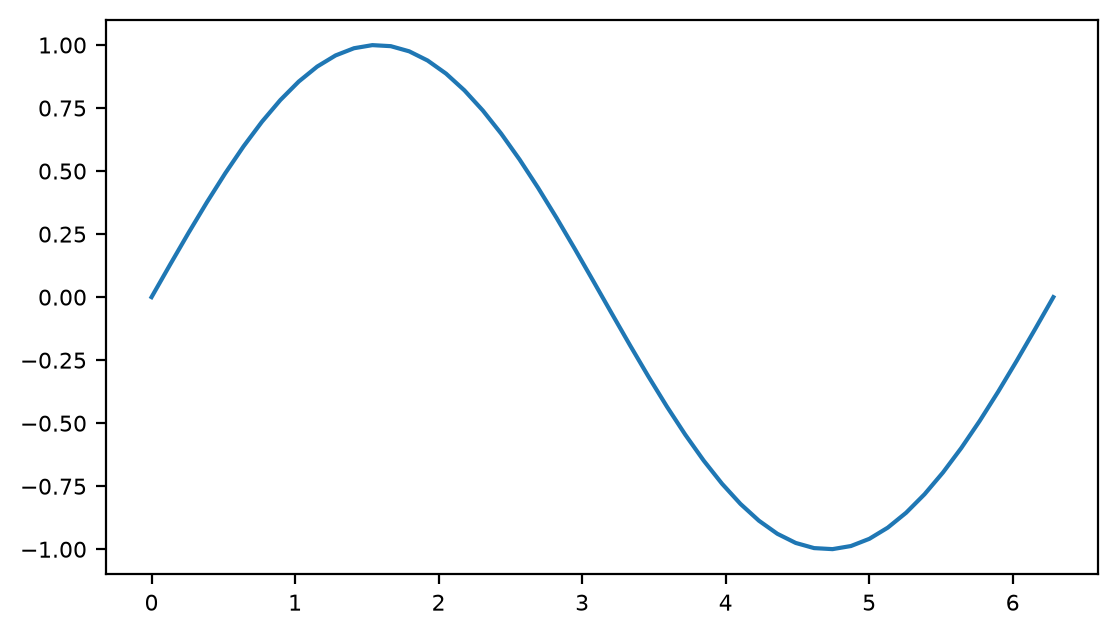

In [191]:
print(np.linspace(0, 1, 5))
x = np.linspace(0, 2 * np.pi, 50)
plt.plot(x, np.sin(x));

[0.   0.25 0.5  0.75 1.  ]


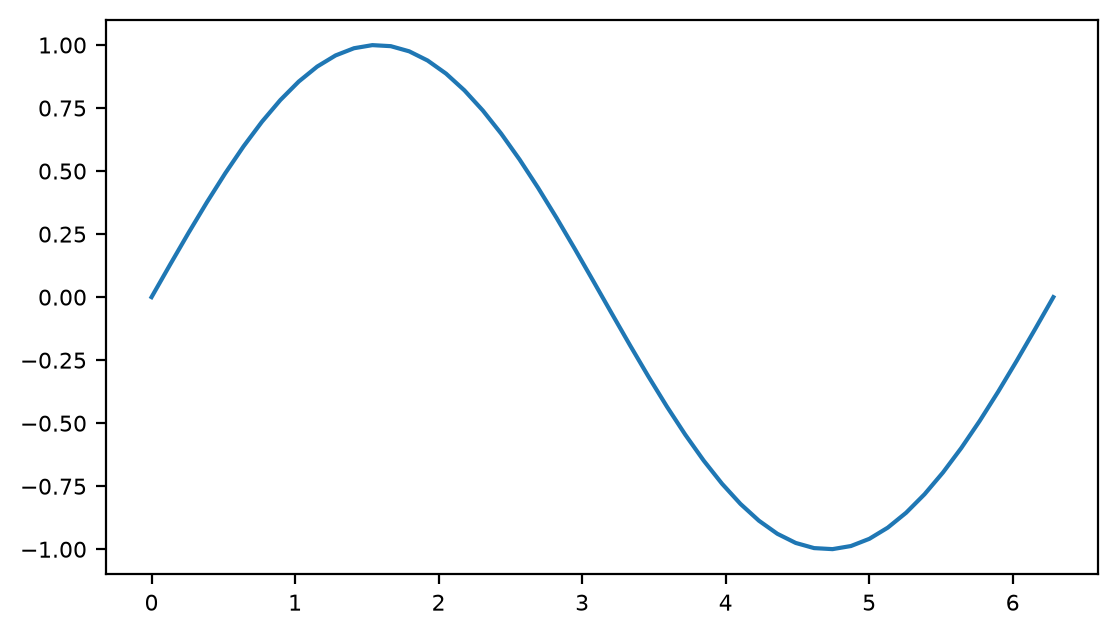

In [192]:
# the same plot in object-oriented style (ax. methods)
print(np.linspace(0, 1, 5))
x = np.linspace(0, 2 * np.pi, 50)
fig, ax = plt.subplots()
ax.plot(x, np.sin(x));

*See also:* Creating a sequence with `np.arange` (A4) · Tables of PDF values (D2) · Applying maths functions to an array (A4)

### Random generators

#### Drawing uniform random numbers

**A4.16**

`np.random.rand(n), np.random.uniform(a, b)`

The `rand` and `uniform` functions allow us to draw random numbers spread evenly over a range. They are useful for simulations and for random noise. Alternatively, `rng.uniform()` from the newer generator does the same.

`rand(n)` gives numbers between 0 and 1; `uniform(a, b)` between a and b.

In [193]:
np.random.seed(1)                    # fixed seed, so the output is repeatable
print(np.random.rand(3))
print(np.random.uniform(5, 10))
print(np.random.uniform(5, 10, 3))

[4.17022005e-01 7.20324493e-01 1.14374817e-04]
6.511662863159199
[5.73377945 5.46169297 5.93130106]


*See also:* Drawing random integers (A4) · Making random numbers repeatable with a seed (A4)

#### Drawing random integers

**A4.17**

`np.random.randint(low, high, size)`

The `np.random.randint` function allows us to draw random whole numbers, such as dice rolls. It is useful for simulating discrete events. Alternatively, `rng.integers()` is the newer equivalent.

The high value is **excluded**, so `randint(1, 7)` simulates a die (1 to 6).

In [194]:
np.random.seed(1)                    # fixed seed, so the output is repeatable
rolls = np.random.randint(1, 7, 100)
print(rolls[:10])
print(f"smallest = {rolls.min()}, largest = {rolls.max()}")
print(f"number of each face = {np.bincount(rolls)[1:].tolist()}")

[6 4 5 1 2 4 6 1 1 2]
smallest = 1, largest = 6
number of each face = [18, 22, 13, 14, 17, 16]


*See also:* Simulating random draws (D1) · Making random numbers repeatable with a seed (A4) · Choosing random items from a list (A4)

#### Drawing normal random numbers

**A4.18**

`np.random.normal(mu, sd, n)`

The `np.random.normal` function allows us to draw numbers from a bell-shaped distribution with a chosen mean and standard deviation. It is useful for simulating measurements. Alternatively, `scipy.stats.norm.rvs()` does the same.

mean = 100.2, sd = 4.9


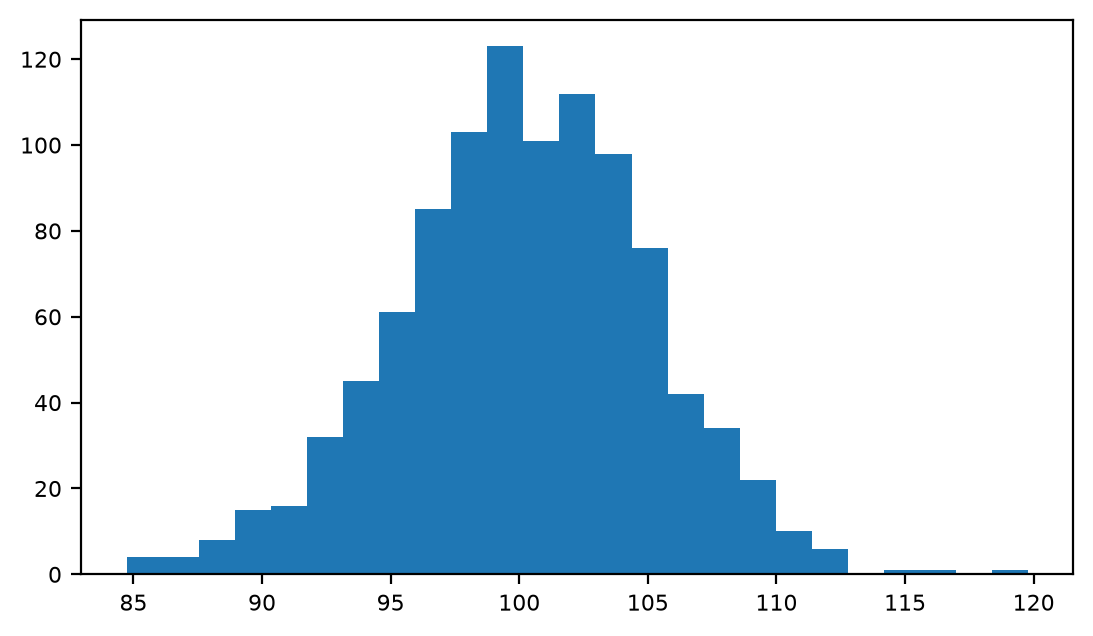

In [195]:
np.random.seed(1)                      # fixed seed, so the output is repeatable
x = np.random.normal(100, 5, 1000)     # mean 100, sd 5, 1000 values
print(f"mean = {x.mean():.1f}, sd = {x.std():.1f}")
plt.hist(x, bins=25);

mean = 100.2, sd = 4.9


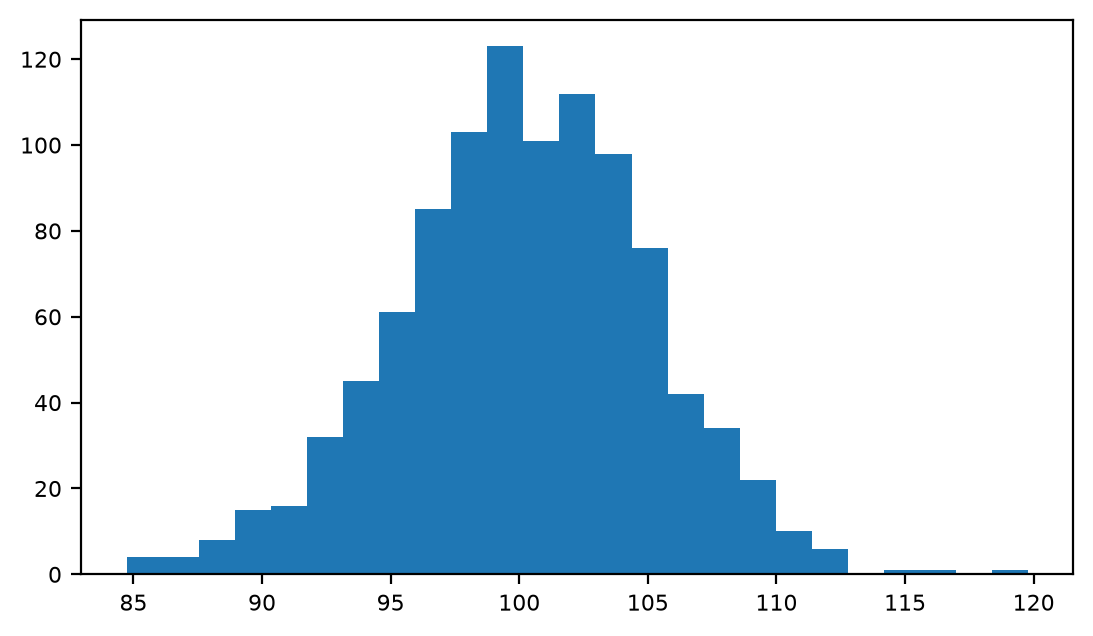

In [196]:
# the same plot in object-oriented style (ax. methods)
np.random.seed(1)                      # fixed seed, so the output is repeatable
x = np.random.normal(100, 5, 1000)     # mean 100, sd 5, 1000 values
print(f"mean = {x.mean():.1f}, sd = {x.std():.1f}")
fig, ax = plt.subplots()
ax.hist(x, bins=25);

*See also:* Random samples with `rvs` (D2) · Comparing a histogram with a normal curve (D2) · Drawing exponential random numbers (A4)

#### Drawing exponential random numbers

**A4.19**

`np.random.exponential(scale, n)`

The `np.random.exponential` function allows us to draw skewed, always-positive numbers. It is useful for demonstrating what non-normal data looks like. Alternatively, `scipy.stats.expon.rvs()` does the same.

The values are skewed: most are small and a few are large.

mean = 1.98


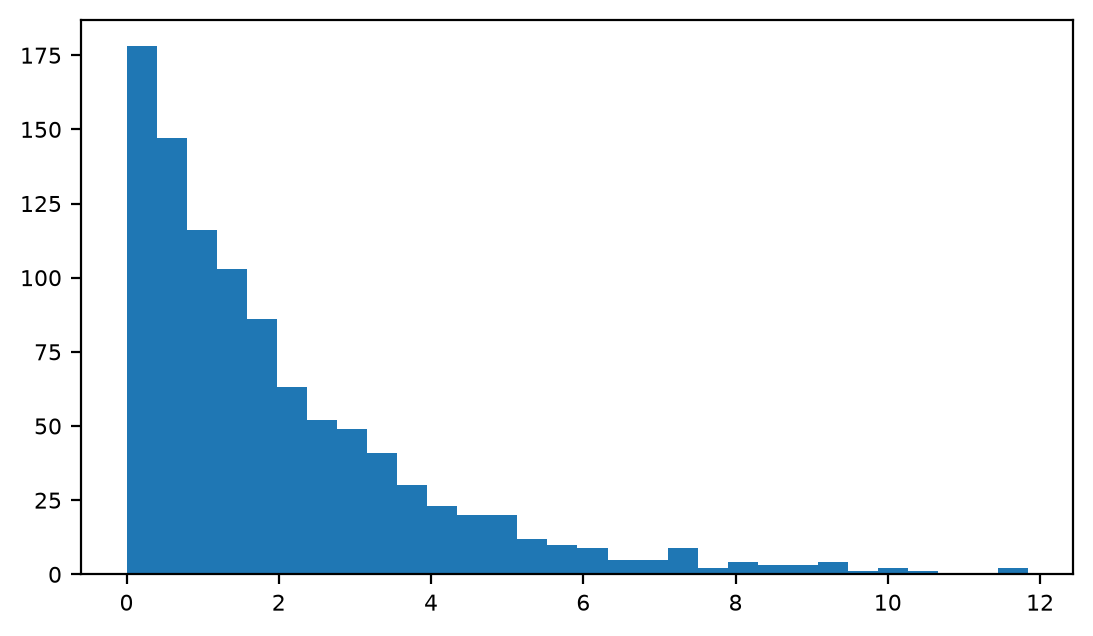

In [197]:
np.random.seed(1)                      # fixed seed, so the output is repeatable
x = np.random.exponential(2, 1000)
print(f"mean = {x.mean():.2f}")
plt.hist(x, bins=30);

mean = 1.98


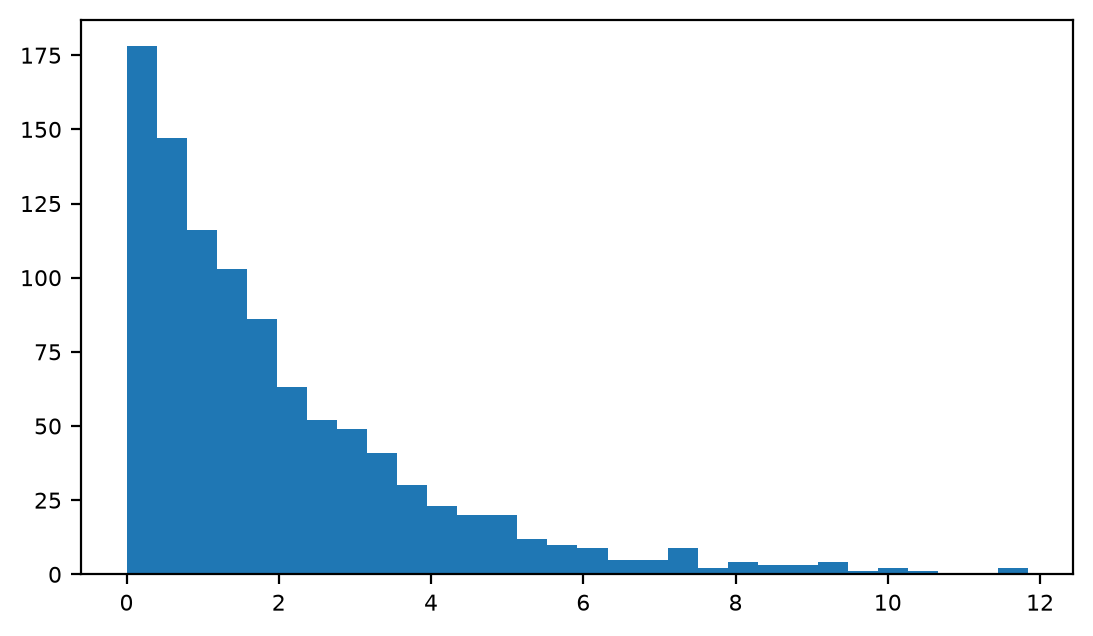

In [198]:
# the same plot in object-oriented style (ax. methods)
np.random.seed(1)                      # fixed seed, so the output is repeatable
x = np.random.exponential(2, 1000)
print(f"mean = {x.mean():.2f}")
fig, ax = plt.subplots()
ax.hist(x, bins=30);

*See also:* Drawing normal random numbers (A4) · The LINE assumptions (D5) · Making random numbers repeatable with a seed (A4)

#### Making random numbers repeatable with a seed

**A4.20**

`np.random.seed(n)`

Setting a seed with `np.random.seed()` allows us to get the same random numbers every time. It is useful so that results (and marking) are repeatable. Alternatively, `np.random.default_rng(seed)` gives a seeded generator object.

Setting a seed gives the same "random" numbers every time the code is run.

In [199]:
np.random.seed(42)

In [200]:
np.random.rand(3)

array([0.37454012, 0.95071431, 0.73199394])

In [201]:
np.random.seed(42)          # same seed again...

In [202]:
np.random.rand(3)    # ...same numbers

array([0.37454012, 0.95071431, 0.73199394])

*See also:* Using the newer random generator (A4) · Drawing uniform random numbers (A4) · Making an analysis repeatable (D6)

#### Using the newer random generator

**A4.21**

`rng = np.random.default_rng(1)`

The `default_rng` function allows us to create a modern, self-contained random number generator. It is useful because its seed does not affect other code. Alternatively, the older `np.random.*` functions still work and are common in notes.

The modern style creates a generator object and calls methods on it. Use `integers` (not `randint`) and `normal`, `uniform`, `choice`.

In [203]:
rng = np.random.default_rng(1)
print(rng.normal(100, 5, 3))
print(rng.integers(1, 7, 5))      # 1 to 6
print(rng.uniform(0, 1, 2))

[101.72792096 104.10809072 101.65218538]
[5 6 2 2 6]
[0.82770259 0.40919914]


*See also:* Making random numbers repeatable with a seed (A4) · Drawing normal random numbers (A4) · Drawing uniform random numbers (A4)

#### Choosing random items from a list

**A4.22**

`np.random.choice(lst, n)`

***(non-examinable)***

The `np.random.choice` function allows us to pick random items from a list. It is useful for sampling or simulating coin flips. Alternatively, `df.sample()` picks random rows from a DataFrame.

In [204]:
np.random.seed(1)                    # fixed seed, so the output is repeatable

In [205]:
np.random.choice(['H', 'T'], 10)

array(['T', 'T', 'H', 'H', 'T', 'T', 'T', 'T', 'T', 'H'], dtype='<U1')

In [206]:
np.random.choice([1, 2, 3, 4, 5], 3, replace=False)   # no repeats

array([3, 4, 5])

*See also:* Looking at random rows (B1) · Drawing random integers (A4) · Drawing uniform random numbers (A4) · Making random numbers repeatable with a seed (A4)

# Part B – pandas